# 03 · EDA visual del proyecto

**Dataset:** All Autoimmune Disorder 10k (Kaggle)  
**Archivo:** `data/processed/autoimmune_cleaned.parquet`  
**Variable objetivo:** `Diagnosis` (116 clases, incluyendo `Normal`)

Este notebook consolida el análisis exploratorio visual del dataset del proyecto. El objetivo no es producir la mayor cantidad de gráficos, sino seleccionar los que permiten entender la estructura de los datos, detectar señales y anticipar riesgos para el modelado:

- distribuciones de las variables clínicas más relevantes;
- comparación de pacientes `Normal` vs. `Autoinmune`;
- relaciones entre marcadores inflamatorios y hematológicos;
- magnitud del desbalance de la variable objetivo.

El análisis usa el dataset limpio generado por el pipeline del proyecto. La columna `Grupo` es una variable auxiliar creada solo para visualización, no forma parte del dataset original.


## Configuración y carga

Se importan las rutas del proyecto y se fija un estilo visual común para todos los gráficos.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

from autoimmune_disorder_prediction.config import CLEANED_DATASET_PATH

NORMAL = "#2A6F97"
AUTO = "#E76F51"
ACCENT = "#2A9D8F"
DARK = "#12263A"
GRAY = "#5C677D"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans",
    rc={
        "axes.edgecolor": "#C9D3DD",
        "axes.labelcolor": DARK,
        "axes.titlecolor": DARK,
        "xtick.color": GRAY,
        "ytick.color": GRAY,
        "grid.color": "#E6ECF1",
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    },
)
pd.set_option("display.max_columns", 30)

df = pd.read_parquet(CLEANED_DATASET_PATH)

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")

df["Grupo"] = np.where(df["Diagnosis"] == "Normal", "Normal", "Autoinmune")
print(df["Grupo"].value_counts().to_string())


Filas: 12,500 | Columnas: 77
Grupo
Autoinmune    10000
Normal         2500


## Ficha del dataset

El dataset contiene **12.500 registros clínicos** y **77 variables** después del saneamiento: edad, sexo, duración de la enfermedad, hemograma, marcadores inflamatorios, complemento, síntomas binarios y paneles de anticuerpos.

La clase `Normal` representa el **20%** de los casos (2.500 registros); los 10.000 restantes se distribuyen entre **115 enfermedades autoinmunes**. Esa estructura —muchas clases y fuerte desbalance— condiciona las métricas y el diseño de validación que se usará más adelante.


In [2]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "nulos": df.isna().sum(),
})
display(resumen.head(15))

display(
    df[["Age", "Sickness_Duration_Months", "CRP", "ESR", "Hemoglobin", "RBC_Count"]]
    .describe()
    .T
    .round(2)
)


,tipo,n_unicos,nulos
Age,int64,67,0
Gender,str,2,0
Diagnosis,str,116,0
Sickness_Duration_Months,int64,120,0
RBC_Count,float64,241,0
Hemoglobin,float64,751,0
Hematocrit,float64,1378,0
MCV,float64,2941,0
MCH,float64,601,0
MCHC,float64,501,0


,count,mean,std,min,25%,50%,75%,max
Age,12500.0,49.76,17.74,18.0,34.00,50.00,65.00,84.0
Sickness_Duration_Months,12500.0,47.96,39.03,0.0,8.00,45.00,82.00,119.0
CRP,12500.0,4.45,3.08,0.0,1.48,4.28,7.14,10.0
ESR,12500.0,25.25,13.37,0.0,14.00,24.00,37.00,49.0
Hemoglobin,12500.0,13.12,1.84,10.0,11.61,13.14,14.41,17.5
RBC_Count,12500.0,4.45,0.57,3.5,3.98,4.46,4.83,5.9


## 1. Distribución de la edad

La edad es la primera variable demográfica a revisar. Interesa conocer su forma, su centro y su dispersión antes de usarla como predictor.


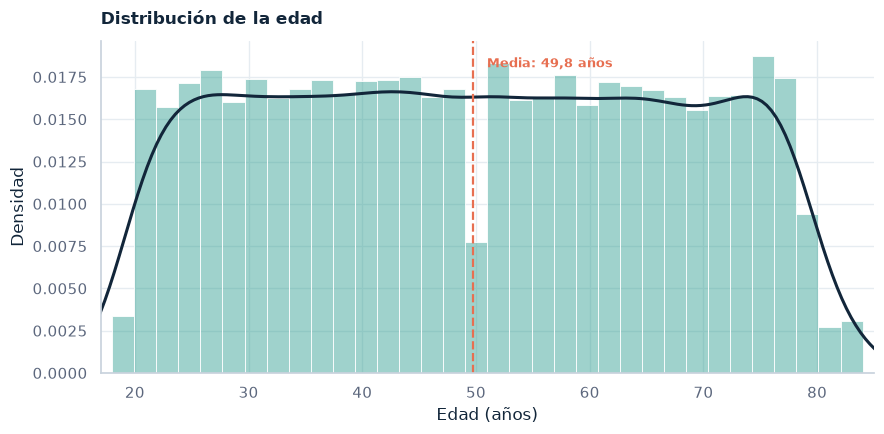

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))

sns.histplot(df["Age"], bins=34, stat="density", color=ACCENT, alpha=0.45,
             edgecolor="white", linewidth=0.6, ax=ax)
sns.kdeplot(df["Age"], color=DARK, linewidth=2.2, ax=ax)

mean_age = df["Age"].mean()
ax.axvline(mean_age, color=AUTO, linestyle="--", linewidth=1.6)
ax.text(mean_age + 1.2, ax.get_ylim()[1] * 0.92,
        f"Media: {mean_age:.1f} años".replace(".", ","),
        color=AUTO, fontsize=9.5, fontweight="bold")

ax.set_xlabel("Edad (años)")
ax.set_ylabel("Densidad")
ax.set_xlim(17, 85)
ax.set_title("Distribución de la edad", loc="left", fontsize=12, fontweight="bold", pad=12)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** La edad se distribuye de forma amplia y casi uniforme entre 18 y 84 años, con media y mediana cercanas a 50. No hay un sesgo marcado ni una cola larga, y la densidad es estable en todo el rango. **Conclusión preliminar:** la edad, por sí sola, no parece un buen separador entre pacientes sanos y autoinmunes; conviene combinarla con otras variables o usarla como variable de ajuste.


## 2. PCR: inflamación y grupos

La proteína C reactiva (PCR) es un marcador de inflamación. Comparar su distribución entre `Normal` y `Autoinmune` permite ver si el marcador separa a los grupos y si hay solapamiento.


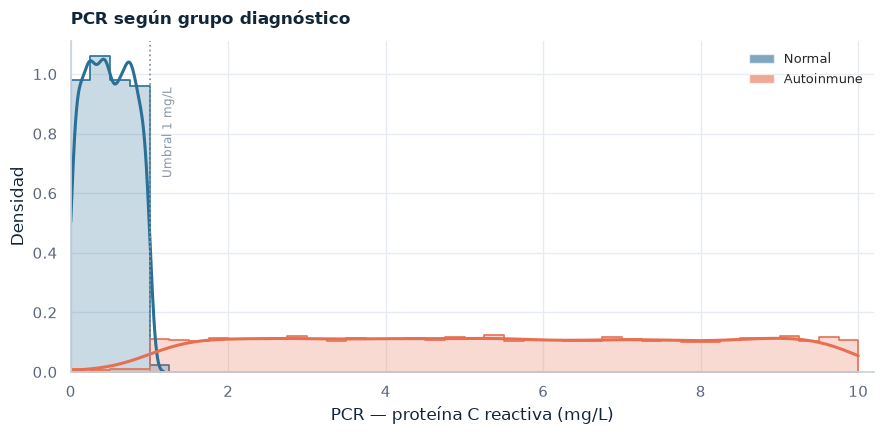

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
palette = {"Normal": NORMAL, "Autoinmune": AUTO}

sns.histplot(
    data=df, x="CRP", hue="Grupo",
    bins=np.arange(0, 10.25, 0.25),
    stat="density", common_norm=False,
    element="step", fill=True, alpha=0.25,
    linewidth=1.2, palette=palette, ax=ax,
)
sns.kdeplot(
    data=df, x="CRP", hue="Grupo", common_norm=False,
    palette=palette, linewidth=2.2, ax=ax, clip=(0, 10), legend=False,
)

ax.axvline(1.0, color="#8A96A3", linestyle=":", linewidth=1.3)
ax.text(1.15, ax.get_ylim()[1] * 0.86, "Umbral 1 mg/L", color="#8A96A3",
        fontsize=8.5, rotation=90, va="top")
ax.set_xlabel("PCR — proteína C reactiva (mg/L)")
ax.set_ylabel("Densidad")
ax.set_xlim(0, 10.2)
ax.set_title("PCR según grupo diagnóstico", loc="left", fontsize=12,
             fontweight="bold", pad=12)
ax.legend(
    handles=[Patch(facecolor=NORMAL, alpha=0.6, label="Normal"),
             Patch(facecolor=AUTO, alpha=0.6, label="Autoinmune")],
    frameon=False, loc="upper right", fontsize=9,
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** El grupo `Normal` se concentra por debajo de 1 mg/L y no supera ese umbral; el grupo autoinmune se extiende hasta 10 mg/L con una forma relativamente plana. La separación es muy fuerte, aunque existe solapamiento en valores bajos. **Conclusión preliminar:** la PCR es una candidata relevante, pero debe revisarse si su medición está disponible antes del diagnóstico para evitar fuga de información.


## 3. VSG y hemoglobina por grupo

La velocidad de sedimentación globular (VSG) y la hemoglobina son dos marcadores clínicos con lecturas complementarias: inflamación y anemia. Los boxplots permiten comparar medianas, dispersión y rangos entre grupos.


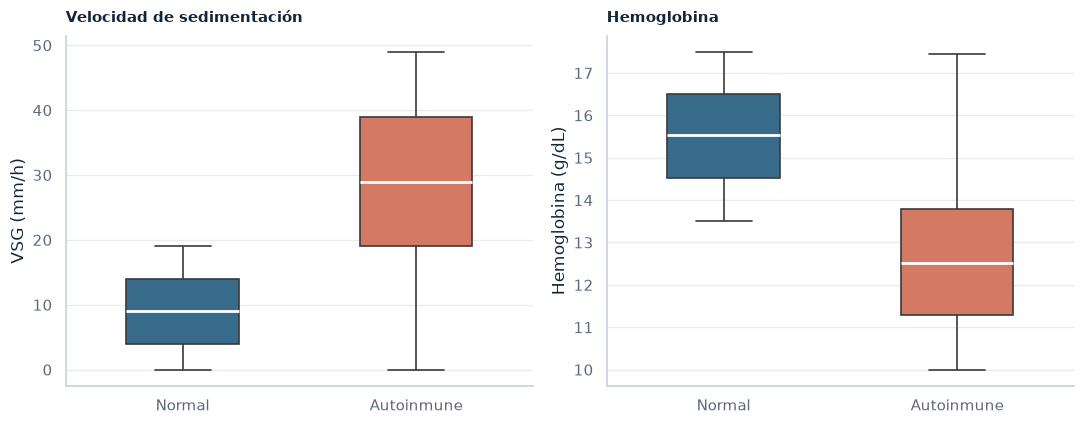

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
palette = {"Normal": NORMAL, "Autoinmune": AUTO}

specs = [
    ("ESR", "VSG (mm/h)", "Velocidad de sedimentación", axes[0]),
    ("Hemoglobin", "Hemoglobina (g/dL)", "Hemoglobina", axes[1]),
]

for column, ylabel, title, ax in specs:
    sns.boxplot(
        data=df, x="Grupo", y=column, hue="Grupo",
        order=["Normal", "Autoinmune"], hue_order=["Normal", "Autoinmune"],
        palette=palette, width=0.48, linewidth=1.2, fliersize=2.2, legend=False,
        medianprops={"color": "white", "linewidth": 2}, ax=ax,
    )
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", pad=10)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()


**Lectura.** La VSG mediana pasa de 9 mm/h en `Normal` a 29 mm/h en autoinmunes, y la hemoglobina cae de 15,5 a 12,5 g/dL. Ambas cajas se desplazan de forma clara, con mayor dispersión en el grupo autoinmune. **Conclusión preliminar:** inflamación elevada y anemia moderada caracterizan al grupo enfermo; son variables útiles para el modelo, siempre que se confirme su disponibilidad temporal.


## 4. PCR y VSG: una correlación engañosa

Un scatter plot con color por grupo permite distinguir una relación individual de una diferencia entre grupos. Este es un control visual clave antes de interpretar cualquier matriz de correlación.


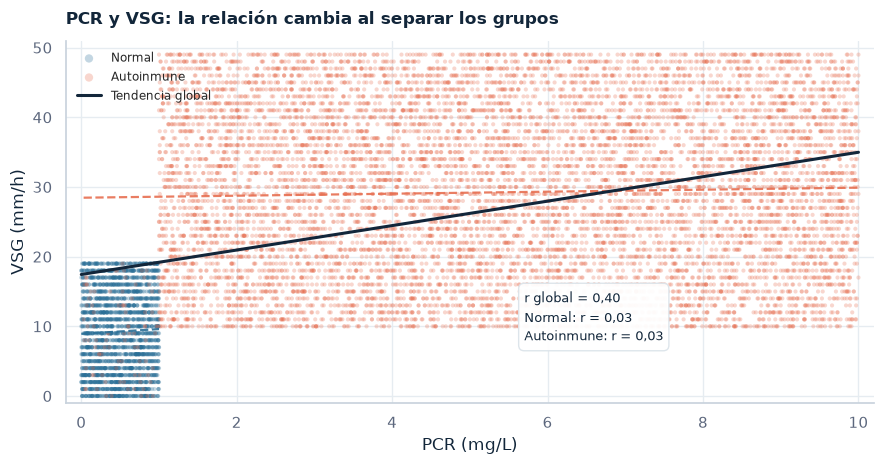

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
palette = {"Normal": NORMAL, "Autoinmune": AUTO}

for group in ["Normal", "Autoinmune"]:
    subset = df[df["Grupo"] == group]
    ax.scatter(subset["CRP"], subset["ESR"], s=9, alpha=0.28,
               color=palette[group], edgecolors="none", label=group)
    slope, intercept = np.polyfit(subset["CRP"], subset["ESR"], 1)
    xs = np.linspace(subset["CRP"].min(), subset["CRP"].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=palette[group],
            linewidth=1.6, linestyle="--", alpha=0.9)

slope, intercept = np.polyfit(df["CRP"], df["ESR"], 1)
xs = np.linspace(0, 10, 50)
ax.plot(xs, slope * xs + intercept, color=DARK, linewidth=2.2,
        label="Tendencia global")

r_all = df["CRP"].corr(df["ESR"])
r_normal = df.loc[df["Grupo"] == "Normal", "CRP"].corr(df.loc[df["Grupo"] == "Normal", "ESR"])
r_auto = df.loc[df["Grupo"] == "Autoinmune", "CRP"].corr(df.loc[df["Grupo"] == "Autoinmune", "ESR"])

ax.set_xlabel("PCR (mg/L)")
ax.set_ylabel("VSG (mm/h)")
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-1, 51)
ax.set_title("PCR y VSG: la relación cambia al separar los grupos", loc="left",
             fontsize=12, fontweight="bold", pad=12)
ax.legend(frameon=False, fontsize=8.8, loc="upper left", markerscale=2)
ax.text(5.7, 8,
        f"r global = {r_all:.2f}\nNormal: r = {r_normal:.2f}\nAutoinmune: r = {r_auto:.2f}".replace(".", ","),
        fontsize=9, color=DARK, linespacing=1.5,
        bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
              "edgecolor": "#DCE4EA", "alpha": 0.95})
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** En el conjunto completo, PCR y VSG parecen correlacionadas (r = 0,40), pero al colorear por grupo la nube se parte en dos y las tendencias internas son planas (r ≈ 0,03). **Conclusión preliminar:** la asociación es un efecto de mezclar sanos y enfermos, no una relación individual. Para modelar hay que estratificar o incluir el grupo; de lo contrario se aprende una correlación espuria.


## 5. Matriz de correlaciones: global vs. autoinmune

El heatmap resume las relaciones lineales entre variables clínicas. Comparar la matriz global con la calculada solo sobre pacientes autoinmunes permite detectar si una correlación está confundida por la diferencia entre grupos.


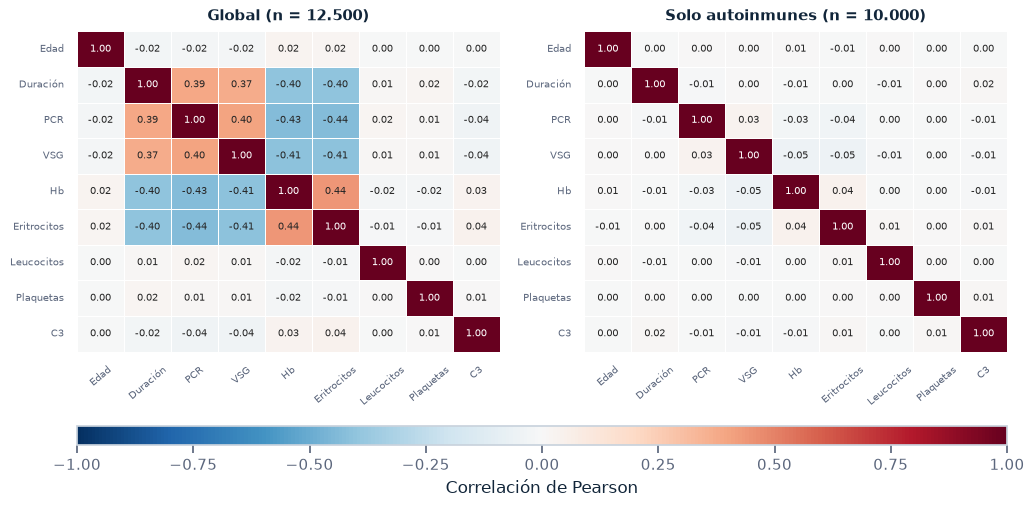

In [7]:
columns = ["Age", "Sickness_Duration_Months", "CRP", "ESR", "Hemoglobin",
           "RBC_Count", "WBC_Count", "PLT_Count", "C3"]
labels = ["Edad", "Duración", "PCR", "VSG", "Hb", "Eritrocitos",
          "Leucocitos", "Plaquetas", "C3"]

corr_all = df[columns].corr()
corr_auto = df[df["Grupo"] == "Autoinmune"][columns].corr()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))

for ax, corr, title in [
    (axes[0], corr_all, f"Global (n = {len(df):,})".replace(",", ".")),
    (axes[1], corr_auto, "Solo autoinmunes (n = 10.000)"),
]:
    annot = corr.round(2).map(lambda v: "0.00" if abs(v) < 0.005 else f"{v:.2f}")
    sns.heatmap(
        corr, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
        annot=annot, fmt="", annot_kws={"size": 7},
        linewidths=0.6, linecolor="white", cbar=False,
        xticklabels=labels, yticklabels=labels,
    )
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=8)
    ax.tick_params(axis="x", labelsize=7.5, rotation=40)
    ax.tick_params(axis="y", labelsize=7.5, rotation=0)

fig.colorbar(axes[1].collections[0], ax=axes, orientation="horizontal",
             fraction=0.05, pad=0.18, aspect=50,
             label="Correlación de Pearson")
plt.show()


**Lectura.** En la matriz global aparecen bloques fuertes: PCR–VSG (0,40), PCR–hemoglobina (–0,43) y duración–PCR (0,39). Al restringir a autoinmunes, casi todas esas correlaciones se desvanecen y solo persiste la relación esperable entre hemoglobina y recuento de eritrocitos. **Conclusión preliminar:** el grupo `Normal` actúa como confusor; el análisis de relaciones debe hacerse dentro de cada subpoblación.


## 6. Duración: una separación perfecta

La duración de la enfermedad es una variable especialmente delicada: si el grupo `Normal` tiene siempre 0 meses, la variable puede predecir el grupo por construcción y convertirse en una fuga de información.


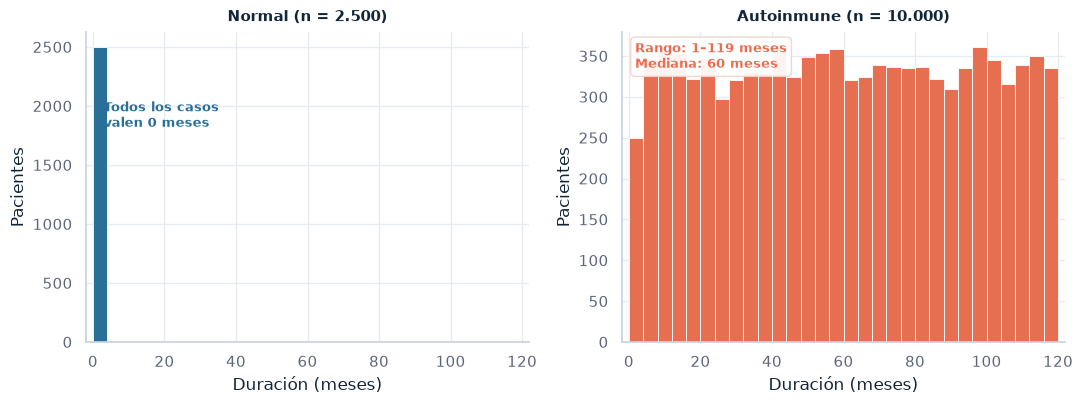

In [8]:
normal = df.loc[df["Grupo"] == "Normal", "Sickness_Duration_Months"]
autoimmune = df.loc[df["Grupo"] == "Autoinmune", "Sickness_Duration_Months"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.arange(0, 124, 4)

axes[0].hist(normal, bins=bins, color=NORMAL, edgecolor="white", linewidth=0.6)
axes[0].set_title("Normal (n = 2.500)", fontsize=10.5, fontweight="bold", pad=8)
axes[0].set_xlabel("Duración (meses)")
axes[0].set_ylabel("Pacientes")
axes[0].set_xlim(-2, 122)
axes[0].text(3, 2050, "Todos los casos\nvalen 0 meses", color=NORMAL,
             fontsize=9, fontweight="bold", va="top")

axes[1].hist(autoimmune, bins=bins, color=AUTO, edgecolor="white", linewidth=0.6)
axes[1].set_title("Autoinmune (n = 10.000)", fontsize=10.5, fontweight="bold", pad=8)
axes[1].set_xlabel("Duración (meses)")
axes[1].set_ylabel("Pacientes")
axes[1].set_xlim(-2, 122)
axes[1].text(0.03, 0.97, "Rango: 1–119 meses\nMediana: 60 meses", color=AUTO,
             transform=axes[1].transAxes, fontsize=9, fontweight="bold", va="top",
             bbox={"boxstyle": "round,pad=0.35", "facecolor": "white",
                   "edgecolor": "#F0D4CB", "alpha": 0.92})

for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** Los 2.500 registros `Normal` tienen exactamente 0 meses de duración, mientras que los 10.000 autoinmunes ocupan todo el rango de 1 a 119 meses (mediana 60). No hay solapamiento: la variable predice el grupo por construcción. **Conclusión preliminar:** es una fuga de información para distinguir `Normal` vs. enfermo; debe excluirse de ese modelo o analizarse solo dentro del subconjunto autoinmune.


## 7. Desbalance de la variable objetivo

Antes de elegir métricas y estrategia de validación, hay que dimensionar el desbalance entre clases.


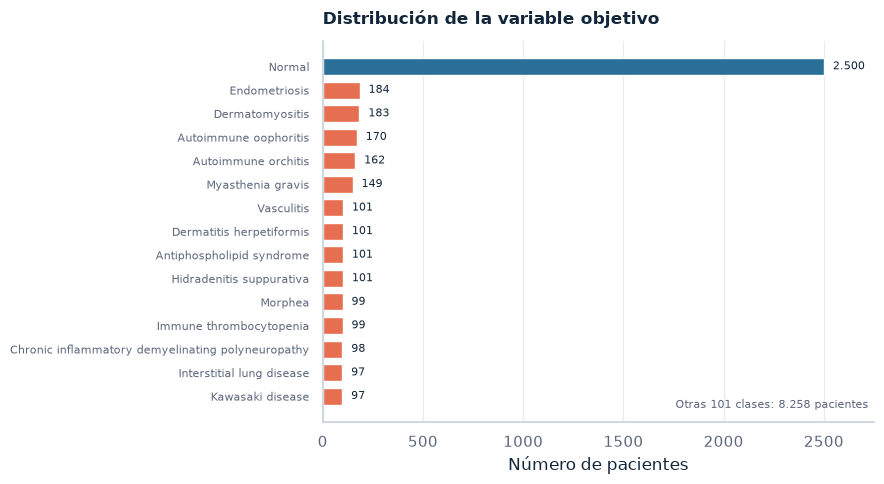

In [9]:
counts = df["Diagnosis"].value_counts()
top = counts.head(15)
values = list(top.values)
names = list(top.index)
order = np.argsort(values)
values = [values[i] for i in order]
names = [names[i] for i in order]

fig, ax = plt.subplots(figsize=(9, 5.0))
colors = [NORMAL if name == "Normal" else AUTO for name in names]
bars = ax.barh(range(len(values)), values, color=colors, height=0.72)
ax.set_yticks(range(len(values)))
ax.set_yticklabels(names, fontsize=8.2)
ax.set_xlabel("Número de pacientes")
ax.set_xlim(0, 2750)
ax.set_title("Distribución de la variable objetivo", loc="left",
             fontsize=12, fontweight="bold", pad=12)

for bar, value in zip(bars, values):
    ax.text(value + 45, bar.get_y() + bar.get_height() / 2,
            f"{value:,}".replace(",", "."), va="center", fontsize=7.8, color=DARK)

remaining = int(counts.iloc[15:].sum())
ax.text(0.99, 0.03, f"Otras {len(counts) - 15} clases: {remaining:,} pacientes".replace(",", "."),
        transform=ax.transAxes, ha="right", va="bottom", fontsize=7.8, color=GRAY)
sns.despine(ax=ax)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


**Lectura.** `Normal` reúne 2.500 pacientes (20%), mientras que las 115 enfermedades autoinmunes se reparten entre 62 y 184 casos cada una; la clase mayoritaria supera a la minoritaria en 40 veces. **Conclusión preliminar:** la exactitud global sería engañosa. Se requiere split estratificado, validación por clase y métricas macro; también conviene separar el problema binario `Normal` vs. autoinmune del problema multiclase entre enfermedades.


## Síntesis y próximos pasos

1. **La edad no discrimina.** Su distribución es amplia y casi plana (media 49,8; mediana 50; rango 18–84). Aporta poco por sí sola.
2. **La inflamación separa los grupos.** La PCR es ≤ 1 mg/L en todos los casos `Normal` y llega a 10 mg/L en autoinmunes. La VSG y la hemoglobina muestran el mismo patrón: medianas de 9 vs. 29 mm/h y 15,5 vs. 12,5 g/dL.
3. **Duración: separación perfecta.** Todos los `Normal` tienen 0 meses y todos los autoinmunes al menos 1. Es una fuga de información para distinguir `Normal` vs. enfermo.
4. **Correlaciones confundidas.** La correlación global PCR–VSG (r = 0,40) desaparece dentro de cada grupo (r ≈ 0,03). Es un caso de paradoja de Simpson.
5. **Desbalance 40:1.** `Normal` concentra 2.500 casos y las 115 enfermedades restantes tienen entre 62 y 184. Se necesita split estratificado, métricas macro y, probablemente, modelos separados: `Normal` vs. autoinmune y, después, tipo de enfermedad.

**Siguiente paso:** construir un baseline estratificado y comparar `Normal` vs. autoinmune antes de abordar las 115 clases. Cualquier modelo que use `Sickness_Duration_Months` para esa comparación estará usando una variable que separa los grupos por construcción.
